In [86]:
import stim
import numpy as np
import pymatching
import itertools

def generate_3_round_pauli2_circuit(target_layer_idx=None, error_component_idx=None, model_prob=0.01, build_base_graph=False):
    """
    Generates a full 3-round surface code circuit.
    
    If build_base_graph=True: Populates all 15 Pauli components across all 8 layers 
                             simultaneously with low noise to define the graph boundaries.
    """
    circuit = stim.Circuit()

    # --- QUBIT REGISTERS MAPPING ---
    def cq(i): return i
    def zq(i): return 9 + i
    def xq(i): return 13 + i
    all_xq = [xq(0), xq(1), xq(2), xq(3)]

    # Structural helper for the uniform syndrome extraction timeline
    def apply_syndrome_cycle(c, round_idx=0):
        c.append("H", all_xq)
        
        # 8 distinct CX gate layers
        layers = [
            [cq(1), zq(1),  cq(3), zq(2),  cq(5), zq(3)], # Layer 0
            [xq(1), cq(0),  xq(2), cq(4),  xq(3), cq(6)], # Layer 1
            [cq(4), zq(1),  cq(6), zq(2),  cq(8), zq(3)], # Layer 2
            [xq(1), cq(1),  xq(2), cq(5),  xq(3), cq(7)], # Layer 3
            [cq(0), zq(0),  cq(2), zq(1),  cq(4), zq(2)], # Layer 4
            [xq(0), cq(1),  xq(1), cq(3),  xq(2), cq(7)], # Layer 5
            [cq(3), zq(0),  cq(5), zq(1),  cq(7), zq(2)], # Layer 6
            [xq(0), cq(2),  xq(1), cq(4),  xq(2), cq(8)]  # Layer 7
        ]
        
        for idx, targets in enumerate(layers):
            c.append("CX", targets)
            
            # --- BASE GRAPH INITIALIZATION ---
            if round_idx == 1 and build_base_graph:
                # Distribute low probability across all 15 components to open all edges
                pauli2_probs = [0.01 / 15] * 15
                c.append("PAULI_CHANNEL_2", targets, pauli2_probs)
            
            # --- TARGETED DETERMINISTIC FAULT TEST RUN ---
            elif round_idx == 1 and target_layer_idx == idx and error_component_idx is not None:
                pauli2_probs = [0.0] * 15
                pauli2_probs[error_component_idx] = model_prob
                c.append("PAULI_CHANNEL_2", targets, pauli2_probs)
                
        c.append("H", all_xq)

    meas_targets = [xq(0), zq(0), xq(1), zq(1), xq(2), zq(2), xq(3), zq(3)]
    
    # ROUND 0: Stable Baseline Initialization
    apply_syndrome_cycle(circuit, round_idx=0)
    circuit.append("M", meas_targets)
    circuit.append("R", meas_targets)
    
    circuit.append("DETECTOR", stim.target_rec(-7))  # zq0
    circuit.append("DETECTOR", stim.target_rec(-5))  # zq1
    circuit.append("DETECTOR", stim.target_rec(-3))  # zq2
    circuit.append("DETECTOR", stim.target_rec(-1))  # zq3

    # ROUND 1: CORRELATED NOISE ZONE
    apply_syndrome_cycle(circuit, round_idx=1)
    circuit.append("M", meas_targets)
    circuit.append("R", meas_targets)
    
    for i in range(8):
        circuit.append("DETECTOR", [stim.target_rec(-8 + i), stim.target_rec(-16 + i)])

    # ROUND 2: Verification Buffer Round
    apply_syndrome_cycle(circuit, round_idx=2)
    circuit.append("M", meas_targets)
    
    for i in range(8):
        circuit.append("DETECTOR", [stim.target_rec(-8 + i), stim.target_rec(-16 + i)])

    # FINAL READOUT DATA DESTRUCTION BOUNDARY
    data_targets = [cq(i) for i in range(9)]
    circuit.append("M", data_targets)

    circuit.append("DETECTOR", [stim.target_rec(-9), stim.target_rec(-6), stim.target_rec(-16)])  # zq0
    circuit.append("DETECTOR", [stim.target_rec(-8), stim.target_rec(-7), stim.target_rec(-5), stim.target_rec(-4), stim.target_rec(-14)])  # zq1
    circuit.append("DETECTOR", [stim.target_rec(-6), stim.target_rec(-5), stim.target_rec(-3), stim.target_rec(-2), stim.target_rec(-12)])  # zq2
    circuit.append("DETECTOR", [stim.target_rec(-4), stim.target_rec(-1), stim.target_rec(-10)])  # zq3

    circuit.append("OBSERVABLE_INCLUDE", [stim.target_rec(-9), stim.target_rec(-8), stim.target_rec(-7)], 0)

    return circuit

# --- MAIN EXECUTION BLOCK ---
if __name__ == "__main__":
    print("--- 3-Round Correlated Noise Analysis via Graph Satiation ---")
    
    pauli2_labels = [
        "IX", "IY", "IZ", 
        "XI", "XX", "XY", "XZ", 
        "YI", "YX", "YY", "YZ", 
        "ZI", "ZX", "ZY", "ZZ"
    ]
    
    # Build global baseline graph topology that map all 15 error choices on all 8 layers
    base_circuit = generate_3_round_pauli2_circuit(build_base_graph=True)
    error_model = base_circuit.detector_error_model(decompose_errors=True, approximate_disjoint_errors=True)
    matching = pymatching.Matching.from_detector_error_model(error_model)
    
    # Loop through all 8 individual CX layers in Round 1
    for layer_idx in range(8):
        print(f"\n--- Testing Round 1 CX Gate Layer {layer_idx} Placements ---")
        
        # Loop through each of the 15 possible Pauli error components
        for comp_idx, label in enumerate(pauli2_labels):
            
            # Generate the test circuit pushing the targeted error type to 0.999 certainty
            test_circuit = generate_3_round_pauli2_circuit(
                target_layer_idx=layer_idx, 
                error_component_idx=comp_idx, 
                model_prob=0.999,
                build_base_graph=False
            )
            
            sampler = test_circuit.compile_detector_sampler()
            det_samples, obs_samples = sampler.sample(shots=1, separate_observables=True)
            
            det_flips = det_samples[0]
            actual_obs = obs_samples[0]
            
            # Decode the syndrome using complete baseline map
            predicted_obs = matching.decode(det_flips)
            
            # Check for logical failure
            status = "PASSED (Corrected)"
            if actual_obs[0] != predicted_obs[0]:
                status = "FAILED (Logical Error)"
                
            print(f"  Error Type {label}: {status}")


--- 3-Round Correlated Noise Analysis via Graph Satiation ---

--- Testing Round 1 CX Gate Layer 0 Placements ---
  Error Type IX: PASSED (Corrected)
  Error Type IY: PASSED (Corrected)
  Error Type IZ: PASSED (Corrected)
  Error Type XI: PASSED (Corrected)
  Error Type XX: FAILED (Catastrophic Logical Error)
  Error Type XY: FAILED (Catastrophic Logical Error)
  Error Type XZ: PASSED (Corrected)
  Error Type YI: PASSED (Corrected)
  Error Type YX: FAILED (Catastrophic Logical Error)
  Error Type YY: FAILED (Catastrophic Logical Error)
  Error Type YZ: PASSED (Corrected)
  Error Type ZI: PASSED (Corrected)
  Error Type ZX: PASSED (Corrected)
  Error Type ZY: PASSED (Corrected)
  Error Type ZZ: PASSED (Corrected)

--- Testing Round 1 CX Gate Layer 1 Placements ---
  Error Type IX: FAILED (Catastrophic Logical Error)
  Error Type IY: FAILED (Catastrophic Logical Error)
  Error Type IZ: PASSED (Corrected)
  Error Type XI: FAILED (Catastrophic Logical Error)
  Error Type XX: PASSED (Correc

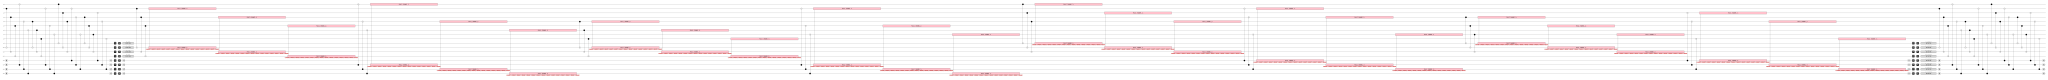

In [84]:
from IPython.display import display

# Generate a static 2D timeline image of the first 4 instructions
svg_text = base_circuit[0:40].diagram(type="timeline-svg")

# Render it natively in Jupyter Notebook cell
display(svg_text)


In [87]:
import stim
import numpy as np
import pymatching
import itertools

def generate_3_round_pauli2_circuit(target_layer_idx=None, target_gate_idx=None, error_component_idx=None, model_prob=0.01, build_base_graph=False):
    """
    Generates a full 3-round surface code circuit.
    
    If build_base_graph=True: Populates all 15 Pauli components across all 8 layers 
                             simultaneously with low noise to define the graph boundaries.
    """
    circuit = stim.Circuit()

    # --- QUBIT REGISTERS MAPPING ---
    def cq(i): return i
    def zq(i): return 9 + i
    def xq(i): return 13 + i
    all_xq = [xq(0), xq(1), xq(2), xq(3)]

    # Structural helper for  uniform syndrome extraction timeline
    def apply_syndrome_cycle(c, round_idx=0):
        c.append("H", all_xq)
        
        # 8 distinct CX gate layers
        layers = [
            [cq(1), zq(1),  cq(3), zq(2),  cq(5), zq(3)], # Layer 0
            [xq(1), cq(0),  xq(2), cq(4),  xq(3), cq(6)], # Layer 1
            [cq(4), zq(1),  cq(6), zq(2),  cq(8), zq(3)], # Layer 2
            [xq(1), cq(1),  xq(2), cq(5),  xq(3), cq(7)], # Layer 3
            [cq(0), zq(0),  cq(2), zq(1),  cq(4), zq(2)], # Layer 4
            [xq(0), cq(1),  xq(1), cq(3),  xq(2), cq(7)], # Layer 5
            [cq(3), zq(0),  cq(5), zq(1),  cq(7), zq(2)], # Layer 6
            [xq(0), cq(2),  xq(1), cq(4),  xq(2), cq(8)]  # Layer 7
        ]
        
        for idx, targets in enumerate(layers):
            c.append("CX", targets)
            
            # --- BASE GRAPH INITIALIZATION ---
            if round_idx == 1 and build_base_graph:
                # Distribute low probability across all 15 components to open all edges
                pauli2_probs = [0.01 / 15] * 15
                c.append("PAULI_CHANNEL_2", targets, pauli2_probs)
            
            # --- TARGETED DETERMINISTIC FAULT TEST RUN ---
            elif round_idx == 1 and target_layer_idx == idx and error_component_idx is not None:
                # Break down unified targets layer list into individual 2-qubit gate slices
                for g_idx in range(len(targets) // 2):
                    gate_slice = targets[g_idx*2 : (g_idx+1)*2]
                    
                    if g_idx == target_gate_idx:
                        # Target gate gets high-probability noise pulse
                        pauli2_probs = [0.0] * 15
                        pauli2_probs[error_component_idx] = model_prob
                        c.append("PAULI_CHANNEL_2", gate_slice, pauli2_probs)
                    else:
                        # Non-targeted gates inside layer remain clean
                        pauli2_probs = [0.0] * 15
                        c.append("PAULI_CHANNEL_2", gate_slice, pauli2_probs)
                
        c.append("H", all_xq)

    meas_targets = [xq(0), zq(0), xq(1), zq(1), xq(2), zq(2), xq(3), zq(3)]
    
    # ROUND 0: Stable Baseline Initialization
    apply_syndrome_cycle(circuit, round_idx=0)
    circuit.append("M", meas_targets)
    circuit.append("R", meas_targets)
    
    circuit.append("DETECTOR", stim.target_rec(-7))  # zq0
    circuit.append("DETECTOR", stim.target_rec(-5))  # zq1
    circuit.append("DETECTOR", stim.target_rec(-3))  # zq2
    circuit.append("DETECTOR", stim.target_rec(-1))  # zq3

    # ROUND 1: CORRELATED NOISE ZONE
    apply_syndrome_cycle(circuit, round_idx=1)
    circuit.append("M", meas_targets)
    circuit.append("R", meas_targets)
    
    for i in range(8):
        circuit.append("DETECTOR", [stim.target_rec(-8 + i), stim.target_rec(-16 + i)])

    # ROUND 2: Verification Buffer Round
    apply_syndrome_cycle(circuit, round_idx=2)
    circuit.append("M", meas_targets)
    
    for i in range(8):
        circuit.append("DETECTOR", [stim.target_rec(-8 + i), stim.target_rec(-16 + i)])

    # FINAL READOUT DATA DESTRUCTION BOUNDARY
    data_targets = [cq(i) for i in range(9)]
    circuit.append("M", data_targets)

    circuit.append("DETECTOR", [stim.target_rec(-9), stim.target_rec(-6), stim.target_rec(-16)])  # zq0
    circuit.append("DETECTOR", [stim.target_rec(-8), stim.target_rec(-7), stim.target_rec(-5), stim.target_rec(-4), stim.target_rec(-14)])  # zq1
    circuit.append("DETECTOR", [stim.target_rec(-6), stim.target_rec(-5), stim.target_rec(-3), stim.target_rec(-2), stim.target_rec(-12)])  # zq2
    circuit.append("DETECTOR", [stim.target_rec(-4), stim.target_rec(-1), stim.target_rec(-10)])  # zq3

    circuit.append("OBSERVABLE_INCLUDE", [stim.target_rec(-9), stim.target_rec(-8), stim.target_rec(-7)], 0)

    return circuit

# --- MAIN EXECUTION BLOCK ---
if __name__ == "__main__":
    print("--- 3-Round Correlated Noise Analysis via Graph Satiation ---")
    
    pauli2_labels = [
        "IX", "IY", "IZ", 
        "XI", "XX", "XY", "XZ", 
        "YI", "YX", "YY", "YZ", 
        "ZI", "ZX", "ZY", "ZZ"
    ]
    
    # Build global baseline graph topology that maps all 15 error choices on all 8 layers
    base_circuit = generate_3_round_pauli2_circuit(build_base_graph=True)
    error_model = base_circuit.detector_error_model(decompose_errors=True, approximate_disjoint_errors=True)
    matching = pymatching.Matching.from_detector_error_model(error_model)
    
    # Loop through all 8 individual CX layers in Round 1
    for layer_idx in range(8):
        print(f"\n=======================================================")
        print(f"Testing Round 1 CX Gate Layer {layer_idx} Placements")
        print(f"=======================================================")
        
        # Identify how many individual gate pairs exist inside this layer
        num_gates_in_layer = 3  # Based on uniform structural mapping array layout
        
        for gate_idx in range(num_gates_in_layer):
            print(f"\n  --> Isolated Gate Index {gate_idx}:")
            
            # Loop through each of the 15 possible Pauli error components
            for comp_idx, label in enumerate(pauli2_labels):
                
                # Generate test circuit pushing isolated target gate error to 0.999 certainty
                test_circuit = generate_3_round_pauli2_circuit(
                    target_layer_idx=layer_idx,
                    target_gate_idx=gate_idx,
                    error_component_idx=comp_idx, 
                    model_prob=0.999,
                    build_base_graph=False
                )
                
                sampler = test_circuit.compile_detector_sampler()
                det_samples, obs_samples = sampler.sample(shots=1, separate_observables=True)
                
                det_flips = det_samples[0]
                actual_obs = obs_samples[0]
                
                # Decode the syndrome using complete baseline map
                predicted_obs = matching.decode(det_flips)
                
                # Check for logical failure
                status = "PASSED (Corrected)"
                if actual_obs[0] != predicted_obs[0]:
                    status = "FAILED (Logical Error)"
                    
                print(f"    Error Type {label}: {status}")


--- 3-Round Correlated Noise Analysis via Graph Satiation ---

Testing Round 1 CX Gate Layer 0 Placements

  --> Isolated Gate Index 0:
    Error Type IX: PASSED (Corrected)
    Error Type IY: PASSED (Corrected)
    Error Type IZ: PASSED (Corrected)
    Error Type XI: PASSED (Corrected)
    Error Type XX: PASSED (Corrected)
    Error Type XY: PASSED (Corrected)
    Error Type XZ: PASSED (Corrected)
    Error Type YI: PASSED (Corrected)
    Error Type YX: PASSED (Corrected)
    Error Type YY: PASSED (Corrected)
    Error Type YZ: PASSED (Corrected)
    Error Type ZI: PASSED (Corrected)
    Error Type ZX: PASSED (Corrected)
    Error Type ZY: PASSED (Corrected)
    Error Type ZZ: PASSED (Corrected)

  --> Isolated Gate Index 1:
    Error Type IX: PASSED (Corrected)
    Error Type IY: PASSED (Corrected)
    Error Type IZ: PASSED (Corrected)
    Error Type XI: PASSED (Corrected)
    Error Type XX: PASSED (Corrected)
    Error Type XY: PASSED (Corrected)
    Error Type XZ: PASSED (Corrected

In [88]:
import stim
import numpy as np
import pymatching
import itertools

def generate_3_round_pauli2_circuit(target_layer_idx=None, target_gate_indices=None, error_component_idx=None, model_prob=0.01, build_base_graph=False):
    """
    Generates a full 3-round surface code circuit.
    
    If build_base_graph=True: Populates all 15 Pauli components across all 8 layers 
                             simultaneously with low noise to define the graph boundaries.
    """
    circuit = stim.Circuit()

    # --- QUBIT REGISTERS MAPPING ---
    def cq(i): return i
    def zq(i): return 9 + i
    def xq(i): return 13 + i
    all_xq = [xq(0), xq(1), xq(2), xq(3)]

    # Structural helper for uniform syndrome extraction timeline
    def apply_syndrome_cycle(c, round_idx=0):
        c.append("H", all_xq)
        
        # 8 distinct CX gate layers
        layers = [
            [cq(1), zq(1),  cq(3), zq(2),  cq(5), zq(3)], # Layer 0
            [xq(1), cq(0),  xq(2), cq(4),  xq(3), cq(6)], # Layer 1
            [cq(4), zq(1),  cq(6), zq(2),  cq(8), zq(3)], # Layer 2
            [xq(1), cq(1),  xq(2), cq(5),  xq(3), cq(7)], # Layer 3
            [cq(0), zq(0),  cq(2), zq(1),  cq(4), zq(2)], # Layer 4
            [xq(0), cq(1),  xq(1), cq(3),  xq(2), cq(7)], # Layer 5
            [cq(3), zq(0),  cq(5), zq(1),  cq(7), zq(2)], # Layer 6
            [xq(0), cq(2),  xq(1), cq(4),  xq(2), cq(8)]  # Layer 7
        ]
        
        for idx, targets in enumerate(layers):
            c.append("CX", targets)
            
            # --- BASE GRAPH INITIALIZATION ---
            if round_idx == 1 and build_base_graph:
                # Distribute low probability across all 15 components to open all edges
                pauli2_probs = [0.01 / 15] * 15
                c.append("PAULI_CHANNEL_2", targets, pauli2_probs)
            
            # --- TARGETED DETERMINISTIC FAULT TEST RUN ---
            elif round_idx == 1 and target_layer_idx == idx and error_component_idx is not None:
                # Break down unified targets layer list into individual 2-qubit gate slices
                for g_idx in range(len(targets) // 2):
                    gate_slice = targets[g_idx*2 : (g_idx+1)*2]
                    
                    if target_gate_indices is not None and g_idx in target_gate_indices:
                        # If gate is in targeted pair, it gets 0.999 fault pulse
                        pauli2_probs = [0.0] * 15
                        pauli2_probs[error_component_idx] = model_prob
                        c.append("PAULI_CHANNEL_2", gate_slice, pauli2_probs)
                    else:
                        # Non-targeted gates inside layer remain clean
                        pauli2_probs = [0.0] * 15
                        c.append("PAULI_CHANNEL_2", gate_slice, pauli2_probs)
                
        c.append("H", all_xq)

    meas_targets = [xq(0), zq(0), xq(1), zq(1), xq(2), zq(2), xq(3), zq(3)]
    
    # ROUND 0: Stable Baseline Initialization
    apply_syndrome_cycle(circuit, round_idx=0)
    circuit.append("M", meas_targets)
    circuit.append("R", meas_targets)
    
    circuit.append("DETECTOR", stim.target_rec(-7))  # zq0
    circuit.append("DETECTOR", stim.target_rec(-5))  # zq1
    circuit.append("DETECTOR", stim.target_rec(-3))  # zq2
    circuit.append("DETECTOR", stim.target_rec(-1))  # zq3

    # ROUND 1: CORRELATED NOISE ZONE
    apply_syndrome_cycle(circuit, round_idx=1)
    circuit.append("M", meas_targets)
    circuit.append("R", meas_targets)
    
    for i in range(8):
        circuit.append("DETECTOR", [stim.target_rec(-8 + i), stim.target_rec(-16 + i)])

    # ROUND 2: Verification Buffer Round
    apply_syndrome_cycle(circuit, round_idx=2)
    circuit.append("M", meas_targets)
    
    for i in range(8):
        circuit.append("DETECTOR", [stim.target_rec(-8 + i), stim.target_rec(-16 + i)])

    # FINAL READOUT DATA DESTRUCTION BOUNDARY
    data_targets = [cq(i) for i in range(9)]
    circuit.append("M", data_targets)

    circuit.append("DETECTOR", [stim.target_rec(-9), stim.target_rec(-6), stim.target_rec(-16)])  # zq0
    circuit.append("DETECTOR", [stim.target_rec(-8), stim.target_rec(-7), stim.target_rec(-5), stim.target_rec(-4), stim.target_rec(-14)])  # zq1
    circuit.append("DETECTOR", [stim.target_rec(-6), stim.target_rec(-5), stim.target_rec(-3), stim.target_rec(-2), stim.target_rec(-12)])  # zq2
    circuit.append("DETECTOR", [stim.target_rec(-4), stim.target_rec(-1), stim.target_rec(-10)])  # zq3

    circuit.append("OBSERVABLE_INCLUDE", [stim.target_rec(-9), stim.target_rec(-8), stim.target_rec(-7)], 0)

    return circuit

# --- MAIN EXECUTION BLOCK ---
if __name__ == "__main__":
    print("--- 3-Round Correlated Noise Analysis via Graph Satiation ---")
    
    pauli2_labels = [
        "IX", "IY", "IZ", 
        "XI", "XX", "XY", "XZ", 
        "YI", "YX", "YY", "YZ", 
        "ZI", "ZX", "ZY", "ZZ"
    ]
    
    # Build a global baseline graph topology
    base_circuit = generate_3_round_pauli2_circuit(build_base_graph=True)
    error_model = base_circuit.detector_error_model(decompose_errors=True, approximate_disjoint_errors=True)
    matching = pymatching.Matching.from_detector_error_model(error_model)
    
    # Loop through all 8 individual CX layers in Round 1
    for layer_idx in range(8):
        print(f"\n=======================================================")
        print(f"Testing Round 1 CX Gate Layer {layer_idx} Placements")
        print(f"=======================================================")
        
        # Generate all possible 2-CX combinations out of the 3 gates in the layer
        num_gates_in_layer = 3
        gate_combinations = list(itertools.combinations(range(num_gates_in_layer), 2))
        
        for combo in gate_combinations:
            print(f"\n  --> Targeted Gate Pair Combination {combo}:")
            
            # Loop through each of the 15 possible Pauli error components
            for comp_idx, label in enumerate(pauli2_labels):
                
                # Generate test circuit pushing the paired gates to 0.999 certainty
                test_circuit = generate_3_round_pauli2_circuit(
                    target_layer_idx=layer_idx,
                    target_gate_indices=combo,
                    error_component_idx=comp_idx, 
                    model_prob=0.999,
                    build_base_graph=False
                )
                
                sampler = test_circuit.compile_detector_sampler()
                det_samples, obs_samples = sampler.sample(shots=1, separate_observables=True)
                
                det_flips = det_samples[0]
                actual_obs = obs_samples[0]
                
                # Decode the syndrome using complete baseline map
                predicted_obs = matching.decode(det_flips)
                
                # Check for logical failure
                status = "PASSED (Corrected)"
                if actual_obs[0] != predicted_obs[0]:
                    status = "FAILED (Logical Error)"
                    
                print(f"    Error Type {label}: {status}")


--- 3-Round Correlated Noise Analysis via Graph Satiation ---

Testing Round 1 CX Gate Layer 0 Placements

  --> Targeted Gate Pair Combination (0, 1):
    Error Type IX: PASSED (Corrected)
    Error Type IY: PASSED (Corrected)
    Error Type IZ: PASSED (Corrected)
    Error Type XI: PASSED (Corrected)
    Error Type XX: PASSED (Corrected)
    Error Type XY: PASSED (Corrected)
    Error Type XZ: PASSED (Corrected)
    Error Type YI: PASSED (Corrected)
    Error Type YX: PASSED (Corrected)
    Error Type YY: PASSED (Corrected)
    Error Type YZ: PASSED (Corrected)
    Error Type ZI: PASSED (Corrected)
    Error Type ZX: PASSED (Corrected)
    Error Type ZY: PASSED (Corrected)
    Error Type ZZ: PASSED (Corrected)

  --> Targeted Gate Pair Combination (0, 2):
    Error Type IX: PASSED (Corrected)
    Error Type IY: PASSED (Corrected)
    Error Type IZ: PASSED (Corrected)
    Error Type XI: PASSED (Corrected)
    Error Type XX: FAILED (Catastrophic Logical Error)
    Error Type XY: FAILED